In [1]:
import numpy as np
import matplotlib.pyplot as plt
import adi

sdr = adi.Pluto("ip:192.168.2.1")
print("Connected")

Connected


In [2]:
sample_rate = int(1e6)        
center_freq = int(915e6)      
buffer_size = 10_000          

sdr.sample_rate = sample_rate
sdr.rx_lo = center_freq
sdr.tx_lo = center_freq

sdr.tx_hardwaregain_chan0 = -30          
sdr.gain_control_mode_chan0 = "manual"   
sdr.rx_hardwaregain_chan0 = 30           

sdr.rx_buffer_size = buffer_size

In [3]:
tone_freq = 100e3                            
t = np.arange(buffer_size) / sample_rate      
tone = np.exp(1j * 2 * np.pi * tone_freq * t) 
tone = tone * 2**14                            

print("Length:", tone.size)
print("Cycles in buffer:", tone_freq * buffer_size / sample_rate, "(should be a whole number)")

Length: 10000
Cycles in buffer: 1000.0 (should be a whole number)


In [4]:
sdr.tx_destroy_buffer()        
sdr.tx_cyclic_buffer = True   
sdr.tx(tone)

for _ in range(5):             
    sdr.rx()

rx = sdr.rx()
print("Received samples:", rx.size)
print("Largest value:", np.max(np.abs(rx)), "(clipping if close to 2048)")

Received samples: 10000
Largest value: 99.53893710503444 (clipping if close to 2048)


In [5]:
sdr.tx_destroy_buffer()
print("Transmit stopped")

Transmit stopped


Strongest signal at 100.0 kHz (expected +100 kHz)


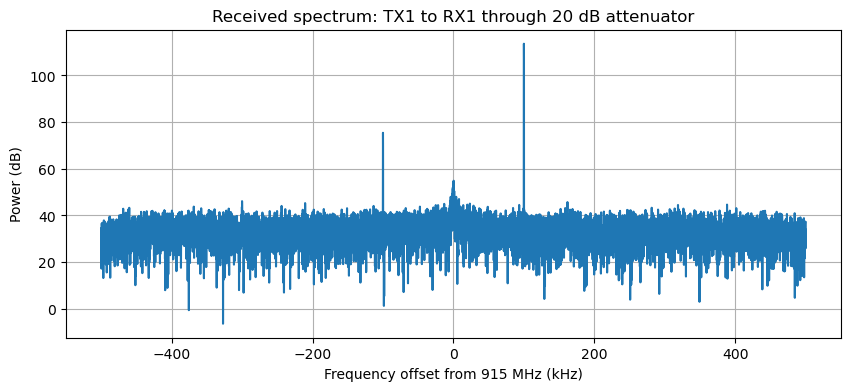

In [6]:
window = np.hanning(buffer_size)                       
spectrum = np.fft.fftshift(np.fft.fft(rx * window))
freqs = np.fft.fftshift(np.fft.fftfreq(buffer_size, d=1/sample_rate))
power_db = 20 * np.log10(np.abs(spectrum) + 1e-12)   

peak_freq = freqs[np.argmax(power_db)]
print(f"Strongest signal at {peak_freq/1e3:.1f} kHz (expected +100 kHz)")

plt.figure(figsize=(10, 4))
plt.plot(freqs / 1e3, power_db)
plt.xlabel("Frequency offset from 915 MHz (kHz)")
plt.ylabel("Power (dB)")
plt.title("Received spectrum: TX1 to RX1 through 20 dB attenuator")
plt.grid(True)
plt.show()